[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/02_training.ipynb)

*Deep Learning & LLMs · Notebook 2 of 10*

# Training Deep Networks

How to make deep networks learn: momentum, RMSProp, Adam and AdamW, learning-rate schedules and warm-up, batch and layer normalisation, gradient clipping, label smoothing, early stopping and gradient accumulation.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Training is a loop: guess, measure the error, find who's to blame, adjust, repeat.

**What interviewers really test here:** Backprop, vanishing gradients, optimisers, normalisation and spotting overfitting.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. The training loop, line by line *(Basics)*
- [ ] 2. Momentum, RMSProp and Adam, by hand *(Core)*
- [ ] 3. Weight decay, and why AdamW exists *(Core)*
- [ ] 4. Learning-rate schedules *(Core)*
- [ ] 5. Batch norm and layer norm, by hand *(Core)*
- [ ] 6. Regularisation and clipping *(Advanced)*
- [ ] 7. A complete PyTorch training loop *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Optimisers

| Name | Update | Notes |
| --- | --- | --- |
| SGD | w −= ηg | simple; good final quality when tuned |
| Momentum | v = μv − ηg; w += v | faster through ravines |
| RMSProp | divide by √(EMA of g²) | per-weight step sizes |
| Adam | momentum + RMSProp + bias correction | good default |
| AdamW | Adam + decoupled decay | default for transformers |

### A practical recipe

1. Overfit a tiny batch to prove the code works.
2. Start with AdamW, lr 1e-3 (or 1e-4 to 3e-5 when fine-tuning a transformer).
3. Use warm-up and cosine decay, with gradient clipping at 1.0.
4. Add regularisation only after you see overfitting.
5. Change one thing at a time; log experiments with their settings.

### Normalisation layers

| Layer | Normalises across | Used in |
| --- | --- | --- |
| BatchNorm | the batch, per feature | CNNs |
| LayerNorm | the features of each example | transformers |
| GroupNorm | groups of channels | small-batch vision |
| RMSNorm | LayerNorm without centring | many modern LLMs |

---
# Part 2: Lessons, step by step

## Lesson 1: The training loop, line by line

*Level: Basics*

All neural network training is this loop:



1. **Take a batch.**
2. **Forward:** compute predictions.
3. **Loss:** measure the error.
4. **Backward:** get every gradient.
5. **Update:** nudge the weights.
6. **Now and then:** check validation data, and save the best model.



#### What to watch



| Curve | Meaning |
| --- | --- |
| Train and validation both falling | keep going |
| Train falling, validation rising | overfitting |
| Both flat and high | learning rate, or model too small |
| Loss becomes NaN | learning rate too high, or a bad input |



**First test for any new model:** can it reach near-zero loss on 10 examples? If not, there's a bug, and more epochs won't help.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

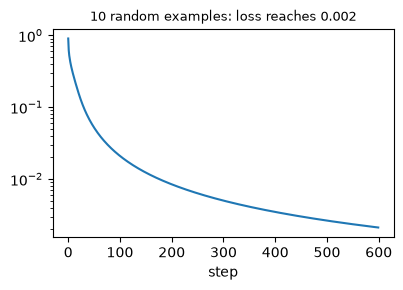

In [2]:
def overfit_tiny_batch():
    r = np.random.default_rng(0)
    X = r.normal(size=(10, 5))
    y = r.integers(0, 2, 10).astype(float)
    W, b = r.normal(0, 0.5, (5, 16)), np.zeros(16)
    W2, b2 = r.normal(0, 0.5, 16), 0.0
    losses = []
    for step in range(600):
        H = np.tanh(X @ W + b)
        p = 1 / (1 + np.exp(-(H @ W2 + b2)))
        losses.append(-(y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)).mean())
        e = p - y
        dH = e[:, None] * W2 * (1 - H ** 2)
        W2 -= 0.5 * H.T @ e / 10
        b2 -= 0.5 * e.mean()
        W -= 0.5 * X.T @ dH / 10
        b -= 0.5 * dH.mean(axis=0)
    fig, ax = plt.subplots(figsize=(4.4, 2.7))
    ax.semilogy(losses)
    ax.set_xlabel("step")
    ax.set_title(f"10 random examples: loss reaches {losses[-1]:.3f}", fontsize=9)


overfit_tiny_batch()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 2: Momentum, RMSProp and Adam, by hand

*Level: Core*

Take w = 1 and gradient 0.5 for three steps, with learning rate 0.1.



| Step | Plain SGD | Momentum (μ = 0.9) |
| --- | --- | --- |
| 1 | 0.95 | v = −0.05, w = 0.95 |
| 2 | 0.90 | v = −0.095, w = 0.855 |
| 3 | 0.85 | v = −0.1355, w = 0.7195 |



When gradients agree, momentum builds up speed; when they keep flipping, they cancel out.



#### RMSProp: divide by the recent gradient size



s ← 0.9s + 0.1g², then w ← w − η·g/√s. Starting from w = 1 with η = 0.01, two gradients of 2 end at **0.9454**, and two gradients of 200 also end at **0.9454**. So the step size no longer depends on the gradient's scale, and each weight effectively gets its own learning rate.



#### Adam combines both



It keeps an average gradient m (momentum) and an average squared gradient v (RMSProp), and corrects both for starting at zero. On the first step, this moves every weight by about the learning rate, whatever its gradient. Sensible default: lr = 0.001.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

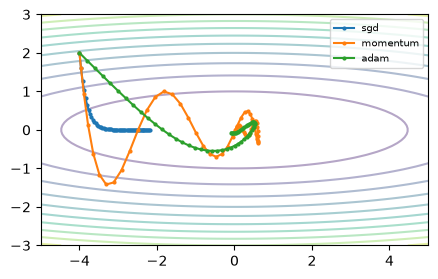

In [3]:
def optimiser_race():
    def grad(p):
        return np.array([0.2 * p[0], 4 * p[1]])

    def run(kind, steps=60, lr=0.05):
        p, m, v = np.array([-4.0, 2.0]), np.zeros(2), np.zeros(2)
        path = [p]
        for t in range(1, steps + 1):
            g = grad(p)
            if kind == "sgd":
                p = p - lr * g
            elif kind == "momentum":
                m = 0.9 * m - lr * g
                p = p + m
            else:
                m = 0.9 * m + 0.1 * g
                v = 0.999 * v + 0.001 * g ** 2
                p = p - 0.2 * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
            path.append(p)
        return np.array(path)

    x, y = np.meshgrid(np.linspace(-5, 5, 80), np.linspace(-3, 3, 80))
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.contour(x, y, 0.1 * x ** 2 + 2 * y ** 2, levels=12, alpha=0.4)
    for kind in ["sgd", "momentum", "adam"]:
        path = run(kind)
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=2, label=kind)
    ax.legend(fontsize=7)


optimiser_race()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. grad() returns array([-0.8,  8. ])
2. grad() returns array([-0.792,  6.4  ])
3. grad() returns array([-0.78408,  5.12   ])
4. grad() returns array([-0.7762392,  4.096    ])
5. grad() returns array([-0.76847681,  3.2768    ])
6. grad() returns array([-0.76079204,  2.62144   ])
7. grad() returns array([-0.75318412,  2.097152  ])
8. grad() returns array([-0.74565228,  1.6777216 ])
9. grad() returns array([-0.73819576,  1.34217728])
10. grad() returns array([-0.7308138 ,  1.07374182])
11. grad() returns array([-0.72350566,  0.85899346])
12. grad() returns array([-0.7162706 ,  0.68719477])  (animation stops after 90 steps)

</details>


**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q10](#q10), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 3: Weight decay, and why AdamW exists

*Level: Core*

**L2 regularisation** adds (λ/2)‖w‖² to the loss, so the gradient gains λw. With zero data gradient, w = 1, lr = 0.1 and λ = 0.5: w becomes 1 − 0.1(0.5) = 0.95. The weight simply shrinks.



#### The problem with Adam



Adam divides by the size of the gradient. If you add λw into the gradient, the decay gets divided too. Look at one step with w = 1, lr = 0.1, λ = 0.1:



| Data gradient | Adam + L2 | AdamW |
| --- | --- | --- |
| 100 | 0.9 | 0.89 |
| 0.001 | 0.9 | 0.89 |



With Adam + L2, the decay is lost: on this first step the update only depends on the sign of the gradient. **AdamW** applies the decay separately, as w − lr·λ·w, so it takes effect at a predictable rate. It's the default for transformers.



Usually don't apply decay to biases and normalisation parameters.

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 4: Learning-rate schedules

*Level: Core*

Early on you want big steps; near the end, small careful ones.



| Schedule | Rate over steps (start at 0.1) |
| --- | --- |
| Step decay (halve every 2) | 0.1, 0.1, 0.05, 0.05, 0.025, 0.025 |
| Cosine (T = 4) | 0.1, 0.0854, 0.05, 0.0146, 0 |
| Warm-up 2, then cosine | 0.05, 0.1, 0.0854, 0.05, 0.0146, 0 |



#### Why warm up?



At the start, random weights give wild gradients, and Adam's running averages are still unreliable. A few gentle steps stop an early blow-up. Warm-up followed by cosine is the standard transformer recipe.



#### Finding a starting rate



Try a **range test**: raise the rate each batch from 1e-6 to 1, and plot the loss. Choose where it falls fastest, somewhat before it blows up.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

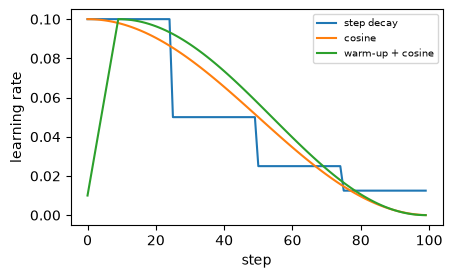

In [4]:
def schedules():
    T = 100
    t = np.arange(T)
    step = 0.1 * 0.5 ** (t // 25)
    cosine = 0.05 * (1 + np.cos(np.pi * t / T))
    warm = np.where(t < 10, 0.1 * (t + 1) / 10, 0.05 * (1 + np.cos(np.pi * (t - 9) / 90)))
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.plot(t, step, label="step decay")
    ax.plot(t, cosine, label="cosine")
    ax.plot(t, warm, label="warm-up + cosine")
    ax.set_xlabel("step")
    ax.set_ylabel("learning rate")
    ax.legend(fontsize=7)


schedules()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q11](#q11), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 5: Batch norm and layer norm, by hand

*Level: Core*

Both rescale values to mean 0, spread 1. The difference is **which way they look**.



```python
X = [[1, 2],
     [3, 4],
     [5, 6]]
```



**Batch norm** works down each **column** (feature). Column 1 has mean 3 and variance 2.667, so it becomes −1.22, 0, 1.22.



**Layer norm** works across each **row** (example). Row (1, 2, 3) has mean 2 and variance 0.667, so it becomes −1.22, 0, 1.22.



|   | Batch norm | Layer norm |
| --- | --- | --- |
| Depends on other examples? | yes | no |
| Small batches | noisy | fine |
| Train vs inference | behaves differently: uses running averages at inference | same |
| Typical use | CNNs | transformers, RNNs |



**Classic bug:** forgetting `model.eval()`, so batch norm uses the current batch when predicting and results change with batch size.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def norm_compare():
    X = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
    batch_norm = ((X - X.mean(axis=0)) / X.std(axis=0)).round(2)
    layer_norm = ((X - X.mean(axis=1, keepdims=True)) / X.std(axis=1, keepdims=True)).round(2)
    Y = np.array([[1.0, 2.0, 3.0]])
    row_result = ((Y - Y.mean()) / Y.std()).round(2)


norm_compare()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 6: Regularisation and clipping

*Level: Advanced*

| Technique | Worked example | What it does |
| --- | --- | --- |
| **Dropout** (keep 0.8) | 4 → 0 or 5 | silence random neurons; divide survivors by keep so the average stays 4 |
| **Label smoothing** (ε = 0.1, k = 3) | [0, 1, 0] → [0.033, 0.933, 0.033] | stops the model chasing 100% certainty |
| **Clip by norm** (max 1) | (3, 4) → (0.6, 0.8) | limits step size; keeps direction |
| **Clip by value** (c = 1) | (3, −4) → (1, −1) | simple, but changes direction |
| **Early stopping** (patience 3) | keep the best epoch | stops before overfitting grows |



#### Early stopping example



Validation losses 1.0, 0.8, 0.7, 0.72, 0.71, 0.73: the best is epoch 2. After 3 epochs with no new best, training stops at epoch 5 and we restore epoch 2. A later dip might have come (patience is a trade-off).



#### Gradient accumulation



Want batch 256 but only 64 fits on the GPU? Run 4 small batches and average their gradients before updating. It gives the same gradient, ignoring batch norm, at the cost of more time.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q5](#q5), [Q7](#q7), [Q15](#q15), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 7: A complete PyTorch training loop

*Level: Advanced*

This code runs as shown on your own machine (PyTorch isn't available in this browser course):



```python
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

for epoch in range(10):
    model.train()                       # dropout and batch norm: training mode
    for xb, yb in loader:
        optimizer.zero_grad()           # clear the old gradients
        loss = loss_fn(model(xb), yb)   # forward + loss
        loss.backward()                 # backward
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()                # update
    scheduler.step()

    model.eval()                        # dropout off; batch norm uses running stats
    with torch.no_grad():               # no gradients needed: faster
        val_logits = model(xb)
```



#### The bugs almost everyone hits



- Forgetting `zero_grad()`: gradients add up across steps.
- Forgetting `model.eval()` for validation.
- Calling `clip_grad_norm_` after `step()`, which is too late.
- Keeping a tensor's graph alive with `total += loss`; use `loss.item()`.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. SGD Update

🟢 Warm-up · *w ← w − η·g*

Return the weights after one SGD step, rounded to 4 decimals.

**Examples**

- `w = [1.0, -2.0], g = [0.5, -1.0], lr = 0.1` → `[0.95, -1.9]`

In [ ]:
def sgd(w, g, lr):
    """
    Return the weights after one SGD step, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sgd, [
    (([1.0, -2.0], [0.5, -1.0], 0.1), [0.95, -1.9]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Update each weight in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vector arithmetic.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Update each weight in a loop.

```python
def sgd(w, g, lr):
    return [round(a - lr * b, 4) for a, b in zip(w, g)]
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vector arithmetic.

```python
def sgd(w, g, lr):
    return (np.array(w) - lr * np.array(g)).round(4)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Update each weight in a loop. That costs O(d) time and O(d) space."

"I can do better: Vector arithmetic. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/sgd-update)

<a id="q2"></a>
### Q2. Step Decay Schedule

🟢 Warm-up · *Drop every few epochs*

lr is multiplied by gamma every step\_size epochs. Return the rate at each of the first n epochs, rounded to 5 decimals.

**Examples**

- `lr = 0.1, gamma = 0.5, step_size = 2, n = 6` → `[0.1, 0.1, 0.05, 0.05, 0.025, 0.025]`

In [ ]:
def step_decay(lr, gamma, step_size, n):
    """
    lr is multiplied by gamma every step_size epochs. Return the rate at each of
    the first n epochs, rounded to 5 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(step_decay, [
    ((0.1, 0.5, 2, 6), [0.1, 0.1, 0.05, 0.05, 0.025, 0.025]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop, dropping when the epoch is a multiple of step\_size.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`lr * gamma ** (epochs // step_size)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop, dropping when the epoch is a multiple of step\_size.

```python
def step_decay(lr, gamma, step_size, n):
    out = []
    current = lr
    for e in range(n):
        if e > 0 and e % step_size == 0:
            current *= gamma
        out.append(round(current, 5))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `lr * gamma ** (epochs // step_size)`.

```python
def step_decay(lr, gamma, step_size, n):
    return (lr * gamma ** (np.arange(n) // step_size)).round(5)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop, dropping when the epoch is a multiple of step\_size. That costs O(n) time and O(n) space."

"I can do better: `lr * gamma ** (epochs // step_size)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/step-decay-schedule)

<a id="q3"></a>
### Q3. Cosine Schedule

🟢 Warm-up · *Smooth decay*

Return lr·½(1 + cos(πt/T)) for each t in 0 … T, rounded to 4 decimals.

**Examples**

- `lr = 0.1, T = 4` → `[0.1, 0.0854, 0.05, 0.0146, 0.0]`

In [ ]:
def cosine_lr(lr, T):
    """
    Return lr·½(1 + cos(πt/T)) for each t in 0 … T, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cosine_lr, [
    ((0.1, 4), [0.1, 0.0854, 0.05, 0.0146, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`math.cos` in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with `np.cos`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** `math.cos` in a loop.

```python
def cosine_lr(lr, T):
    return [round(lr * 0.5 * (1 + math.cos(math.pi * t / T)), 4) + 0.0 for t in range(T + 1)]
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised with `np.cos`.

```python
def cosine_lr(lr, T):
    t = np.arange(T + 1)
    return (lr * 0.5 * (1 + np.cos(np.pi * t / T))).round(4) + 0.0
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `math.cos` in a loop. That costs O(T) time and O(T) space."

"I can do better: Vectorised with `np.cos`. That's O(T) time and O(T) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/cosine-schedule)

<a id="q4"></a>
### Q4. Clip Gradients by Norm

🟢 Warm-up · *Stops explosions*

If ‖g‖ exceeds max\_norm, scale g down to that length. Round to 4 decimals.

**Examples**

- `g = [3.0, 4.0], max_norm = 1.0` → `[0.6, 0.8]`
- `g = [0.3, 0.4], max_norm = 1.0` → `[0.3, 0.4]`

In [ ]:
def clip_norm(g, max_norm):
    """
    If ‖g‖ exceeds max_norm, scale g down to that length. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clip_norm, [
    (([3.0, 4.0], 1.0), [0.6, 0.8]),
    (([0.3, 0.4], 1.0), [0.3, 0.4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the length in a loop, then scale.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`g * min(1, max_norm / norm)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute the length in a loop, then scale.

```python
def clip_norm(g, max_norm):
    norm = math.sqrt(sum(x * x for x in g))
    if norm <= max_norm:
        return [round(x, 4) for x in g]
    return [round(x * max_norm / norm, 4) for x in g]
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `g * min(1, max_norm / norm)`.

```python
def clip_norm(g, max_norm):
    g = np.array(g)
    return (g * min(1.0, max_norm / np.linalg.norm(g))).round(4)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the length in a loop, then scale. That costs O(d) time and O(d) space."

"I can do better: `g * min(1, max_norm / norm)`. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/clip-gradients-by-norm)

<a id="q5"></a>
### Q5. Clip Gradients by Value

🟢 Warm-up · *Keeps it simple, changes direction*

Limit each entry to [−c, c].

**Examples**

- `g = [3.0, -4.0, 0.5], c = 1.0` → `[1.0, -1.0, 0.5]`

In [ ]:
def clip_value(g, c):
    """
    Limit each entry to [−c, c].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clip_value, [
    (([3.0, -4.0, 0.5], 1.0), [1.0, -1.0, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`max(-c, min(c, x))`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.clip`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** `max(-c, min(c, x))`.

```python
def clip_value(g, c):
    return [max(-c, min(c, x)) for x in g]
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.clip`.

```python
def clip_value(g, c):
    return np.clip(g, -c, c)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `max(-c, min(c, x))`. That costs O(d) time and O(d) space."

"I can do better: `np.clip`. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/clip-gradients-by-value)

<a id="q6"></a>
### Q6. L2 Penalty in the Gradient

🟢 Warm-up · *Weight decay*

With loss + (λ/2)‖w‖², the gradient becomes g + λw. Return one SGD step from w, rounded to 4 decimals.

**Examples**

- `w = [1.0, -2.0], g = [0.0, 0.0], lr = 0.1, lam = 0.5` → `[0.95, -1.9]`
- `w = [1.0, -2.0], g = [1.0, 1.0], lr = 0.1, lam = 0.5` → `[0.85, -2.0]`

In [ ]:
def l2_step(w, g, lr, lam):
    """
    With loss + (λ/2)‖w‖², the gradient becomes g + λw. Return one SGD step from
    w, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(l2_step, [
    (([1.0, -2.0], [0.0, 0.0], 0.1, 0.5), [0.95, -1.9]),
    (([1.0, -2.0], [1.0, 1.0], 0.1, 0.5), [0.85, -2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Adjust each gradient in a loop, then step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`w - lr * (g + lam * w)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Adjust each gradient in a loop, then step.

```python
def l2_step(w, g, lr, lam):
    return [round(a - lr * (b + lam * a), 4) for a, b in zip(w, g)]
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `w - lr * (g + lam * w)`.

```python
def l2_step(w, g, lr, lam):
    w = np.array(w)
    return (w - lr * (np.array(g) + lam * w)).round(4)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Adjust each gradient in a loop, then step. That costs O(d) time and O(d) space."

"I can do better: `w - lr * (g + lam * w)`. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/l2-penalty-in-the-gradient)

<a id="q7"></a>
### Q7. Label Smoothing

🟢 Warm-up · *Don't aim for 100%*

Return one-hot targets for the labels with smoothing: y(1 − ε) + ε/k, rounded to 4 decimals.

**Examples**

- `y = [1, 0], k = 3, eps = 0.1` → `[[0.0333, 0.9333, 0.0333], [0.9333, 0.0333, 0.0333]]`

In [ ]:
def smooth_labels(y, k, eps):
    """
    Return one-hot targets for the labels with smoothing: y(1 − ε) + ε/k,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(smooth_labels, [
    (([1, 0], 3, 0.1), [[0.0333, 0.9333, 0.0333], [0.9333, 0.0333, 0.0333]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.eye(k)[y] * (1 - eps) + eps / k`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops.

```python
def smooth_labels(y, k, eps):
    return [[round((1.0 if c == label else 0.0) * (1 - eps) + eps / k, 4) for c in range(k)] for label in y]
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.eye(k)[y] * (1 - eps) + eps / k`.

```python
def smooth_labels(y, k, eps):
    return (np.eye(k)[y] * (1 - eps) + eps / k).round(4)
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops. That costs O(n·k) time and O(n·k) space."

"I can do better: `np.eye(k)[y] * (1 - eps) + eps / k`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/label-smoothing)

<a id="q8"></a>
### Q8. Smoothing a Loss Curve

🟢 Warm-up · *EMA with bias correction*

Return the smoothed curve: s ← βs + (1 − β)x from s = 0, reported as s/(1 − βᵗ), rounded to 4 decimals.

**Examples**

- `x = [1.0, 0.0, 1.0], beta = 0.5` → `[1.0, 0.3333, 0.7143]`

In [ ]:
def smooth_curve(x, beta):
    """
    Return the smoothed curve: s ← βs + (1 − β)x from s = 0, reported as s/(1 −
    βᵗ), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(smooth_curve, [
    (([1.0, 0.0, 1.0], 0.5), [1.0, 0.3333, 0.7143]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A weighted average of the values so far, with weights βᵏ.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop.

```python
def smooth_curve(x, beta):
    s, out = 0.0, []
    for t, v in enumerate(x, start=1):
        s = beta * s + (1 - beta) * v
        out.append(round(s / (1 - beta ** t), 4))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A weighted average of the values so far, with weights βᵏ.

```python
def smooth_curve(x, beta):
    x = np.array(x, dtype=float)
    out = []
    for t in range(len(x)):
        weights = beta ** np.arange(t, -1, -1)
        out.append(round((x[:t + 1] * weights).sum() / weights.sum(), 4))
    return out
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(n) space."

"I can do better: A weighted average of the values so far, with weights βᵏ. That's O(n²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/smoothing-a-loss-curve)

<a id="q9"></a>
### Q9. SGD With Momentum

🟡 Interview standard · *Velocity*

Apply gradient steps for the given list of gradients, with v ← μv − η·g and w ← w + v, starting at v = 0. Return the final w, rounded to 4 decimals.

**Examples**

- `w = 1.0, grads = [0.5, 0.5, 0.5], lr = 0.1, mu = 0.9` → `0.7195`

In [ ]:
def momentum(w, grads, lr, mu):
    """
    Apply gradient steps for the given list of gradients, with v ← μv − η·g and
    w ← w + v, starting at v = 0. Return the final w, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(momentum, [
    ((1.0, [0.5, 0.5, 0.5], 0.1, 0.9), 0.7195),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop over the gradients.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Each update is a discounted sum: use powers of μ with `np.cumsum`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop over the gradients.

```python
def momentum(w, grads, lr, mu):
    v = 0.0
    for g in grads:
        v = mu * v - lr * g
        w = w + v
    return round(w, 4)
```

**Cost:** O(steps) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Each update is a discounted sum: use powers of μ with `np.cumsum`.

```python
def momentum(w, grads, lr, mu):
    g = np.array(grads)
    velocities = [-lr * (g[:t + 1] * mu ** np.arange(t, -1, -1)).sum() for t in range(len(g))]
    return round(w + float(np.sum(velocities)), 4)
```

**Cost:** O(steps²) time, O(steps) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop over the gradients. That costs O(steps) time and O(1) space."

"I can do better: Each update is a discounted sum: use powers of μ with `np.cumsum`. That's O(steps²) time and O(steps) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/sgd-with-momentum)

<a id="q10"></a>
### Q10. RMSProp Step Sizes

🟡 Interview standard · *Divide by recent gradient size*

Run RMSProp on one weight: s ← βs + (1 − β)g², w ← w − η·g/√(s + ε) with β = 0.9, ε = 1e-8, s₀ = 0. Return the final w, rounded to 4 decimals.

**Examples**

- `w = 1.0, grads = [2.0, 2.0], lr = 0.01` → `0.9454`
- `w = 1.0, grads = [200.0, 200.0], lr = 0.01` → `0.9454`

In [ ]:
def rmsprop(w, grads, lr):
    """
    Run RMSProp on one weight: s ← βs + (1 − β)g², w ← w − η·g/√(s + ε) with β =
    0.9, ε = 1e-8, s₀ = 0. Return the final w, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rmsprop, [
    ((1.0, [2.0, 2.0], 0.01), 0.9454),
    ((1.0, [200.0, 200.0], 0.01), 0.9454),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The running average in closed form with weights 0.1·0.9ᵏ.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop.

```python
def rmsprop(w, grads, lr):
    s = 0.0
    for g in grads:
        s = 0.9 * s + 0.1 * g * g
        w = w - lr * g / math.sqrt(s + 1e-8)
    return round(w, 4)
```

**Cost:** O(steps) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The running average in closed form with weights 0.1·0.9ᵏ.

```python
def rmsprop(w, grads, lr):
    g = np.array(grads, dtype=float)
    for t in range(len(g)):
        s = (0.1 * g[:t + 1] ** 2 * 0.9 ** np.arange(t, -1, -1)).sum()
        w = w - lr * g[t] / np.sqrt(s + 1e-8)
    return round(float(w), 4)
```

**Cost:** O(steps²) time, O(steps) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(steps) time and O(1) space."

"I can do better: The running average in closed form with weights 0.1·0.9ᵏ. That's O(steps²) time and O(steps) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/rmsprop-step-sizes)

<a id="q11"></a>
### Q11. Warm-Up Then Cosine

🟡 Interview standard · *The transformer schedule*

Rise linearly from lr/warm up to lr over the first warm steps, then cosine to 0 by the end. Return the rate at each of T steps, rounded to 4 decimals.

**Examples**

- `lr = 0.1, warm = 2, T = 6` → `[0.05, 0.1, 0.0854, 0.05, 0.0146, 0.0]`

In [ ]:
def warm_cosine(lr, warm, T):
    """
    Rise linearly from lr/warm up to lr over the first warm steps, then cosine
    to 0 by the end. Return the rate at each of T steps, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(warm_cosine, [
    ((0.1, 2, 6), [0.05, 0.1, 0.0854, 0.05, 0.0146, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An if/else per step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.where` on the step array.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** An if/else per step.

```python
def warm_cosine(lr, warm, T):
    out = []
    for t in range(T):
        if t < warm:
            value = lr * (t + 1) / warm
        else:
            value = lr * 0.5 * (1 + math.cos(math.pi * (t - warm + 1) / (T - warm)))
        out.append(round(value, 4) + 0.0)
    return out
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.where` on the step array.

```python
def warm_cosine(lr, warm, T):
    t = np.arange(T)
    cosine = lr * 0.5 * (1 + np.cos(np.pi * (t - warm + 1) / (T - warm)))
    return np.where(t < warm, lr * (t + 1) / warm, cosine).round(4) + 0.0
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An if/else per step. That costs O(T) time and O(T) space."

"I can do better: `np.where` on the step array. That's O(T) time and O(T) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/warm-up-then-cosine)

<a id="q12"></a>
### Q12. Batch Normalisation

🟡 Interview standard · *Per feature, across the batch*

Return (x − mean)/√(var + 1e-5) for each column of the batch (population variance), rounded to 4 decimals.

**Examples**

- `X = [[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]]` → `[[-1.2247, -1.2247], [0.0, 0.0], [1.2247, 1.2247]]`

In [ ]:
def batch_norm(X):
    """
    Return (x − mean)/√(var + 1e-5) for each column of the batch (population
    variance), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(batch_norm, [
    (([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]],), [[-1.2247, -1.2247], [0.0, 0.0], [1.2247, 1.2247]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Mean and variance per column in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`X.mean(axis=0)`, `X.var(axis=0)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Mean and variance per column in loops.

```python
def batch_norm(X):
    n, d = len(X), len(X[0])
    out = [[0.0] * d for _ in range(n)]
    for j in range(d):
        col = [row[j] for row in X]
        mean = sum(col) / n
        var = sum((v - mean) ** 2 for v in col) / n
        for i in range(n):
            out[i][j] = round((col[i] - mean) / math.sqrt(var + 1e-5), 4) + 0.0
    return out
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `X.mean(axis=0)`, `X.var(axis=0)`.

```python
def batch_norm(X):
    X = np.array(X)
    return ((X - X.mean(axis=0)) / np.sqrt(X.var(axis=0) + 1e-5)).round(4) + 0.0
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Mean and variance per column in loops. That costs O(n·d) time and O(d) space."

"I can do better: `X.mean(axis=0)`, `X.var(axis=0)`. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/batch-normalisation)

<a id="q13"></a>
### Q13. Layer Normalisation

🟡 Interview standard · *Per row: used in transformers*

Return (x − mean)/√(var + 1e-5) within each row (population variance), rounded to 4 decimals.

**Examples**

- `X = [[1.0, 2.0, 3.0], [10.0, 10.0, 40.0]]` → `[[-1.2247, 0.0, 1.2247], [-0.7071, -0.7071, 1.4142]]`

In [ ]:
def layer_norm(X):
    """
    Return (x − mean)/√(var + 1e-5) within each row (population variance),
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(layer_norm, [
    (([[1.0, 2.0, 3.0], [10.0, 10.0, 40.0]],), [[-1.2247, 0.0, 1.2247], [-0.7071, -0.7071, 1.4142]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Mean and variance per row in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`axis=1, keepdims=True`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Mean and variance per row in loops.

```python
def layer_norm(X):
    out = []
    for row in X:
        mean = sum(row) / len(row)
        var = sum((v - mean) ** 2 for v in row) / len(row)
        out.append([round((v - mean) / math.sqrt(var + 1e-5), 4) + 0.0 for v in row])
    return out
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `axis=1, keepdims=True`.

```python
def layer_norm(X):
    X = np.array(X)
    return ((X - X.mean(axis=1, keepdims=True)) / np.sqrt(X.var(axis=1, keepdims=True) + 1e-5)).round(4) + 0.0
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Mean and variance per row in loops. That costs O(n·d) time and O(n·d) space."

"I can do better: `axis=1, keepdims=True`. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/layer-normalisation)

<a id="q14"></a>
### Q14. Running Statistics for Inference

🟡 Interview standard · *Exponential moving average*

Batch norm keeps a running mean: r ← (1 − m)·r + m·batch\_mean, starting at 0. Return it after the given batch means, rounded to 4 decimals (m = 0.1).

**Examples**

- `means = [2.0, 2.0, 2.0]` → `0.542`
- `means = [1.0, 3.0]` → `0.39`

In [ ]:
def running_mean(means):
    """
    Batch norm keeps a running mean: r ← (1 − m)·r + m·batch_mean, starting at
    0. Return it after the given batch means, rounded to 4 decimals (m = 0.1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(running_mean, [
    (([2.0, 2.0, 2.0],), 0.542),
    (([1.0, 3.0],), 0.39),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Closed form: Σ m·(1 − m)^(n−1−i)·xᵢ.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop.

```python
def running_mean(means):
    r = 0.0
    for x in means:
        r = 0.9 * r + 0.1 * x
    return round(r, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Closed form: Σ m·(1 − m)^(n−1−i)·xᵢ.

```python
def running_mean(means):
    x = np.array(means)
    return round((0.1 * x * 0.9 ** np.arange(len(x) - 1, -1, -1)).sum(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(1) space."

"I can do better: Closed form: Σ m·(1 − m)^(n−1−i)·xᵢ. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/running-statistics-for-inference)

<a id="q15"></a>
### Q15. Dropout During Training

🟡 Interview standard · *Keep, then rescale*

Keep each value when np.random.RandomState(seed).rand(n) is below keep, and divide kept values by keep so the average is unchanged. Round to 4 decimals.

**Examples**

- `a = [1.0, 2.0, 3.0, 4.0], keep = 0.8, seed = 0` → `[1.25, 2.5, 3.75, 5.0]`

In [ ]:
def dropout(a, keep, seed):
    """
    Keep each value when np.random.RandomState(seed).rand(n) is below keep, and
    divide kept values by keep so the average is unchanged. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dropout, [
    (([1.0, 2.0, 3.0, 4.0], 0.8, 0), [1.25, 2.5, 3.75, 5.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

One random draw per value.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A mask times the array.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** One random draw per value.

```python
def dropout(a, keep, seed):
    rng = np.random.RandomState(seed)
    return [round(v / keep, 4) if rng.rand() < keep else 0.0 for v in a]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A mask times the array.

```python
def dropout(a, keep, seed):
    mask = np.random.RandomState(seed).rand(len(a)) < keep
    return (np.array(a) * mask / keep).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: One random draw per value. That costs O(n) time and O(n) space."

"I can do better: A mask times the array. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/dropout-during-training)

<a id="q16"></a>
### Q16. Early Stopping

🟡 Interview standard · *Know when to stop*

Given validation losses, stop after patience epochs with no new best. Return (epoch to keep — the best so far, epoch where training stopped), counting from 0.

**Examples**

- `losses = [1.0, 0.8, 0.7, 0.72, 0.71, 0.73, 0.6], patience = 3` → `(2, 5)`
- `losses = [1.0, 0.9, 0.8], patience = 2` → `(2, 2)`

In [ ]:
def early_stop(losses, patience):
    """
    Given validation losses, stop after patience epochs with no new best. Return
    (epoch to keep — the best so far, epoch where training stopped), counting
    from 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(early_stop, [
    (([1.0, 0.8, 0.7, 0.72, 0.71, 0.73, 0.6], 3), (2, 5)),
    (([1.0, 0.9, 0.8], 2), (2, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track the best and a counter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.minimum.accumulate` shows where new bests happen.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Track the best and a counter.

```python
def early_stop(losses, patience):
    best, best_epoch, waited = float("inf"), 0, 0
    for e, loss in enumerate(losses):
        if loss < best:
            best, best_epoch, waited = loss, e, 0
        else:
            waited += 1
            if waited >= patience:
                return (best_epoch, e)
    return (best_epoch, len(losses) - 1)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.minimum.accumulate` shows where new bests happen.

```python
def early_stop(losses, patience):
    x = np.array(losses)
    prior = np.r_[np.inf, np.minimum.accumulate(x)[:-1]]
    new_best = np.flatnonzero(x < prior)
    for a, b in zip(new_best, np.r_[new_best[1:], len(x)]):
        if b - a > patience:
            return (int(a), int(a + patience))
    return (int(new_best[-1]), len(x) - 1)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track the best and a counter. That costs O(n) time and O(1) space."

"I can do better: `np.minimum.accumulate` shows where new bests happen. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/early-stopping)

<a id="q17"></a>
### Q17. Gradient Accumulation

🟡 Interview standard · *Big batch on a small GPU*

Gradients from equal-sized micro-batches are averaged before one update. Return the update's weights: w − lr·mean(grads), rounded to 4 decimals.

**Examples**

- `w = [1.0, 2.0], grads = [[0.2, 0.4], [0.4, 0.8]], lr = 0.5` → `[0.85, 1.7]`

In [ ]:
def accumulate(w, grads, lr):
    """
    Gradients from equal-sized micro-batches are averaged before one update.
    Return the update's weights: w − lr·mean(grads), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(accumulate, [
    (([1.0, 2.0], [[0.2, 0.4], [0.4, 0.8]], 0.5), [0.85, 1.7]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up gradients in loops, divide, then update.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.mean(grads, axis=0)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up gradients in loops, divide, then update.

```python
def accumulate(w, grads, lr):
    total = [0.0] * len(w)
    for g in grads:
        for i, v in enumerate(g):
            total[i] += v
    return [round(a - lr * t / len(grads), 4) for a, t in zip(w, total)]
```

**Cost:** O(m·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.mean(grads, axis=0)`.

```python
def accumulate(w, grads, lr):
    return (np.array(w) - lr * np.mean(grads, axis=0)).round(4)
```

**Cost:** O(m·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up gradients in loops, divide, then update. That costs O(m·d) time and O(d) space."

"I can do better: `np.mean(grads, axis=0)`. That's O(m·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/gradient-accumulation)

<a id="q18"></a>
### Q18. Pick a Learning Rate From a Range Test

🟡 Interview standard · *Steepest fall*

Losses were measured while raising the rate. Return the rate where the loss fell most compared with the previous point.

**Examples**

- `rates = [0.0001, 0.001, 0.01, 0.1, 1.0], losses = [2.3, 2.25, 1.8, 1.0, 5.0]` → `0.1`

In [ ]:
def pick_rate(rates, losses):
    """
    Losses were measured while raising the rate. Return the rate where the loss
    fell most compared with the previous point.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pick_rate, [
    (([0.0001, 0.001, 0.01, 0.1, 1.0], [2.3, 2.25, 1.8, 1.0, 5.0]), 0.1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track the biggest drop in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.diff(losses).argmin() + 1`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Track the biggest drop in a loop.

```python
def pick_rate(rates, losses):
    best_i, best_drop = 1, float("inf")
    for i in range(1, len(losses)):
        change = losses[i] - losses[i - 1]
        if change < best_drop:
            best_i, best_drop = i, change
    return rates[best_i]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.diff(losses).argmin() + 1`.

```python
def pick_rate(rates, losses):
    return rates[int(np.diff(losses).argmin()) + 1]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track the biggest drop in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.diff(losses).argmin() + 1`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/pick-a-learning-rate-from-a-range-test)

<a id="q19"></a>
### Q19. Adam With Bias Correction

🔴 Stretch · *The default optimiser*

Run Adam on the weight vector for the list of gradient vectors (β₁ = 0.9, β₂ = 0.999, ε = 1e-8). Return final weights, rounded to 4 decimals.

**Examples**

- `w = [1.0, -1.0], grads = [[0.5, 100.0], [0.5, 100.0]], lr = 0.1` → `[0.8, -1.2]`

In [ ]:
def adam(w, grads, lr):
    """
    Run Adam on the weight vector for the list of gradient vectors (β₁ = 0.9, β₂
    = 0.999, ε = 1e-8). Return final weights, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(adam, [
    (([1.0, -1.0], [[0.5, 100.0], [0.5, 100.0]], 0.1), [0.8, -1.2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lists of m and v for each weight.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vector operations.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Lists of m and v for each weight.

```python
def adam(w, grads, lr):
    w = list(w)
    m, v = [0.0] * len(w), [0.0] * len(w)
    for t, g in enumerate(grads, start=1):
        for i in range(len(w)):
            m[i] = 0.9 * m[i] + 0.1 * g[i]
            v[i] = 0.999 * v[i] + 0.001 * g[i] ** 2
            m_hat = m[i] / (1 - 0.9 ** t)
            v_hat = v[i] / (1 - 0.999 ** t)
            w[i] -= lr * m_hat / (math.sqrt(v_hat) + 1e-8)
    return [round(x, 4) for x in w]
```

**Cost:** O(steps·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vector operations.

```python
def adam(w, grads, lr):
    w = np.array(w, dtype=float)
    m, v = np.zeros_like(w), np.zeros_like(w)
    for t, g in enumerate(np.array(grads, dtype=float), start=1):
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g ** 2
        w = w - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
    return w.round(4)
```

**Cost:** O(steps·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lists of m and v for each weight. That costs O(steps·d) time and O(d) space."

"I can do better: Vector operations. That's O(steps·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/adam-with-bias-correction)

<a id="q20"></a>
### Q20. AdamW vs L2 Penalty

🔴 Stretch · *Decoupled weight decay*

One step from w with gradient g, lr, decay d. Return (Adam with L2 — adds d·w to g first; AdamW — subtracts lr·d·w separately), rounded to 4 decimals.

**Examples**

- `w = 1.0, g = 100.0, lr = 0.1, d = 0.1` → `(0.9, 0.89)`
- `w = 1.0, g = 0.001, lr = 0.1, d = 0.1` → `(0.9, 0.89)`

In [ ]:
def adamw_compare(w, g, lr, d):
    """
    One step from w with gradient g, lr, decay d. Return (Adam with L2 — adds
    d·w to g first; AdamW — subtracts lr·d·w separately), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(adamw_compare, [
    ((1.0, 100.0, 0.1, 0.1), (0.9, 0.89)),
    ((1.0, 0.001, 0.1, 0.1), (0.9, 0.89)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run the first Adam step by hand both ways.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

On step 1 the bias-corrected ratio is g/|g|, so Adam moves by exactly lr·sign(g).

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Run the first Adam step by hand both ways.

```python
def adamw_compare(w, g, lr, d):
    def first_step(weight, gradient):
        m = 0.1 * gradient
        v = 0.001 * gradient ** 2
        return weight - lr * (m / (1 - 0.9)) / (math.sqrt(v / (1 - 0.999)) + 1e-8)

    with_l2 = first_step(w, g + d * w)
    adamw = first_step(w, g) - lr * d * w
    return (round(with_l2, 4), round(adamw, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** On step 1 the bias-corrected ratio is g/|g|, so Adam moves by exactly lr·sign(g).

```python
def adamw_compare(w, g, lr, d):
    with_l2 = w - lr * np.sign(g + d * w)
    adamw = w - lr * np.sign(g) - lr * d * w
    return (round(float(with_l2), 4), round(float(adamw), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run the first Adam step by hand both ways. That costs O(1) time and O(1) space."

"I can do better: On step 1 the bias-corrected ratio is g/|g|, so Adam moves by exactly lr·sign(g). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/training/adamw-vs-l2-penalty)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Adam vs SGD?</b></summary>

Adam converges fast with little tuning. SGD with momentum and a good schedule can generalise slightly better in some vision tasks. Start with Adam or AdamW.

</details>

<details>
<summary><b>2. Why warm up the learning rate?</b></summary>

Early gradients are large and unreliable, and Adam's averages haven't settled, so a small starting rate prevents the training from blowing up.

</details>

<details>
<summary><b>3. Batch norm vs layer norm?</b></summary>

Batch norm normalises each feature across the batch and depends on batch size. Layer norm normalises each example across features, works at batch size 1, and is the norm for sequence models.

</details>

<details>
<summary><b>4. Why is gradient clipping used?</b></summary>

A rare extreme gradient can destroy the weights in one step. Clipping limits the update size while keeping the direction, which is especially useful for RNNs and transformers.

</details>

<details>
<summary><b>5. What is gradient accumulation?</b></summary>

Summing gradients over several small batches before an update, to simulate a larger batch than fits in memory.

</details>

<details>
<summary><b>6. What is label smoothing?</b></summary>

Replacing hard 0/1 targets with slightly softened ones. It reduces overconfidence and can improve generalisation.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: The training loop, line by line
- [ ] I can explain: Momentum, RMSProp and Adam, by hand
- [ ] I can explain: Weight decay, and why AdamW exists
- [ ] I can explain: Learning-rate schedules
- [ ] I can explain: Batch norm and layer norm, by hand
- [ ] I can explain: Regularisation and clipping
- [ ] I can explain: A complete PyTorch training loop

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Early Stopping
- [ ] [Q17](#q17) Gradient Accumulation
- [ ] [Q18](#q18) Pick a Learning Rate From a Range Test
- [ ] [Q19](#q19) Adam With Bias Correction
- [ ] [Q20](#q20) AdamW vs L2 Penalty

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.